<a href="https://colab.research.google.com/github/SlastuninAE/python-practice-algos/blob/master/636-01/hw_5_slastunin_a_e.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install kagglehub --quiet

In [3]:
import kagglehub
path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mnist-dataset' dataset.
Path to dataset files: /kaggle/input/mnist-dataset


In [47]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
import struct
import os
from pathlib import Path
from collections import Counter

In [13]:
for dirpath, dirnames, filenames in os.walk(path):
    depth = dirpath.replace(path, "").count(os.sep)
    if depth <= 2:  # не углубляемся слишком сильно
        indent = "  " * depth
        print(f"{indent}{os.path.basename(dirpath)}/")
        if filenames:
            print(f"{indent}  └── файлов: {len(filenames)}, примеры: {filenames[:3]}")

mnist-dataset/
  └── файлов: 4, примеры: ['train-images.idx3-ubyte', 't10k-labels.idx1-ubyte', 't10k-images.idx3-ubyte']
  t10k-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['t10k-labels-idx1-ubyte']
  t10k-images-idx3-ubyte/
    └── файлов: 1, примеры: ['t10k-images-idx3-ubyte']
  train-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['train-labels-idx1-ubyte']
  train-images-idx3-ubyte/
    └── файлов: 1, примеры: ['train-images-idx3-ubyte']


In [14]:
ROOT = "/kaggle/input/mnist-dataset"

def read_idx_images(path):
    """Читает IDX-файл с изображениями → массив (N, rows*cols)."""
    with open(path, 'rb') as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        # Проверяем магическое число (2051 = 0x00000803)
        assert magic == 2051, f"Неверный magic number в {path}: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
        data = data.reshape(n, rows * cols)
    return data.astype(np.float32)

def read_idx_labels(path):
    """Читает IDX-файл с метками → массив (N,)."""
    with open(path, 'rb') as f:
        magic, n = struct.unpack(">II", f.read(8))
        # Проверяем магическое число (2049 = 0x00000801)
        assert magic == 2049, f"Неверный magic number в {path}: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.astype(int)

def load_mnist_idx(root_dir):
    """
    Загружает MNIST из IDX-файлов в стиле MedMNIST:
    возвращает (X_train, y_train, X_val, y_val, X_test, y_test).

    MNIST: 60000 train + 10000 test. Отделяем 10% от train под validation.
    """
    root = Path(root_dir)

    # Ищем файлы в корне (могут быть с дефисами или подчёркиваниями)
    def find_file(*candidates):
        for name in candidates:
            p = root / name
            if p.exists():
                return p
            # ищем рекурсивно на случай вложенных папок
            for sub in root.rglob(name):
                return sub
        raise FileNotFoundError(
            f"Не найден файл среди: {candidates} в {root_dir}"
        )

    train_images = find_file(
        "train-images.idx3-ubyte",
        "train-images-idx3-ubyte",
    )
    train_labels = find_file(
        "train-labels.idx1-ubyte",
        "train-labels-idx1-ubyte",
    )
    test_images = find_file(
        "t10k-images.idx3-ubyte",
        "t10k-images-idx3-ubyte",
    )
    test_labels = find_file(
        "t10k-labels.idx1-ubyte",
        "t10k-labels-idx1-ubyte",
    )

    print(f"Train images: {train_images}")
    print(f"Train labels: {train_labels}")
    print(f"Test  images: {test_images}")
    print(f"Test  labels: {test_labels}")

    # Загружаем
    X_train_full = read_idx_images(train_images)
    y_train_full = read_idx_labels(train_labels)
    X_test       = read_idx_images(test_images)
    y_test       = read_idx_labels(test_labels)

    # Отделяем validation (10% от train, стратифицированно)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full,
        test_size=0.1,
        random_state=42,
        stratify=y_train_full,
    )

    # Нормализация пикселей: [0, 255] → [0, 1]
    # В MedMNIST данные уже в [0, 1], приводим MNIST к тому же виду
    X_train = X_train / 255.0
    X_val   = X_val   / 255.0
    X_test  = X_test  / 255.0

    print(f"\nTrain:      X={X_train.shape}, y={y_train.shape}")
    print(f"Validation: X={X_val.shape},   y={y_val.shape}")
    print(f"Test:       X={X_test.shape},  y={y_test.shape}")

    return X_train, y_train, X_val, y_val, X_test, y_test

In [15]:
X_train, y_train, X_val, y_val, X_test, y_test = load_mnist_idx(ROOT)

Train images: /kaggle/input/mnist-dataset/train-images.idx3-ubyte
Train labels: /kaggle/input/mnist-dataset/train-labels.idx1-ubyte
Test  images: /kaggle/input/mnist-dataset/t10k-images.idx3-ubyte
Test  labels: /kaggle/input/mnist-dataset/t10k-labels.idx1-ubyte

Train:      X=(54000, 784), y=(54000,)
Validation: X=(6000, 784),   y=(6000,)
Test:       X=(10000, 784),  y=(10000,)


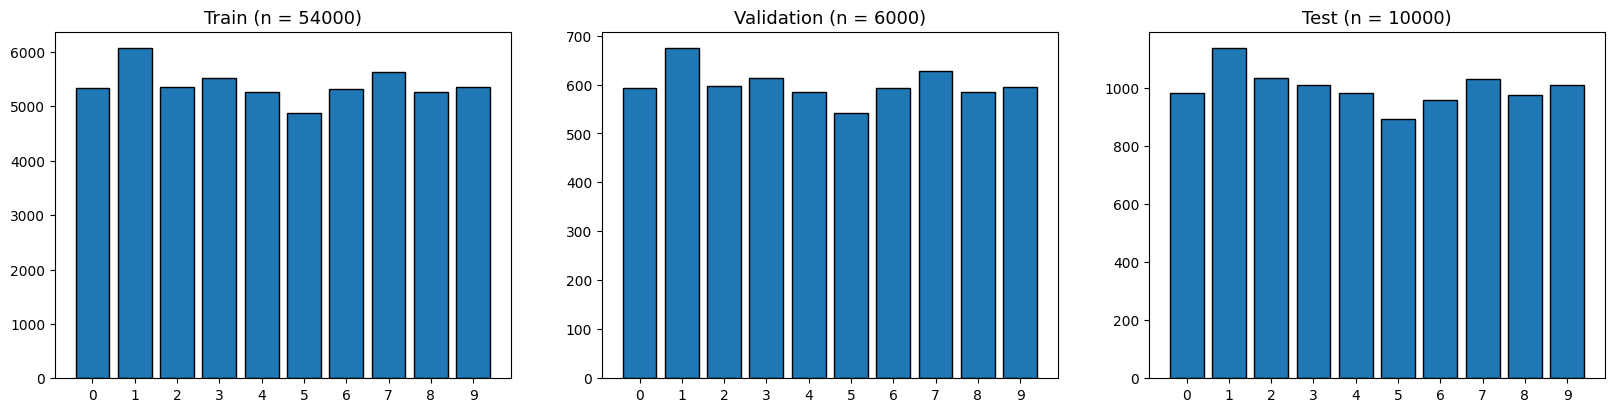

In [31]:
def plot_class_balance(y_train, y_val, y_test):
    fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))

    datasets = [
        ("Train", y_train, axes[0]),
        ("Validation", y_val, axes[1]),
        ("Test", y_test, axes[2]),
    ]

    for name, y, ax in datasets:
        counts = Counter(y)
        classes = sorted(counts.keys())
        labels = [f"{c}" for c in classes]
        values = [counts[c] for c in classes]
        total = sum(values)

        bars = ax.bar(labels, values, edgecolor='black')
        ax.set_title(f"{name} (n = {total})", fontsize=13)
        for bar, v in zip(bars, values):
            pct = 100 * v / total

plot_class_balance(y_train, y_val, y_test)

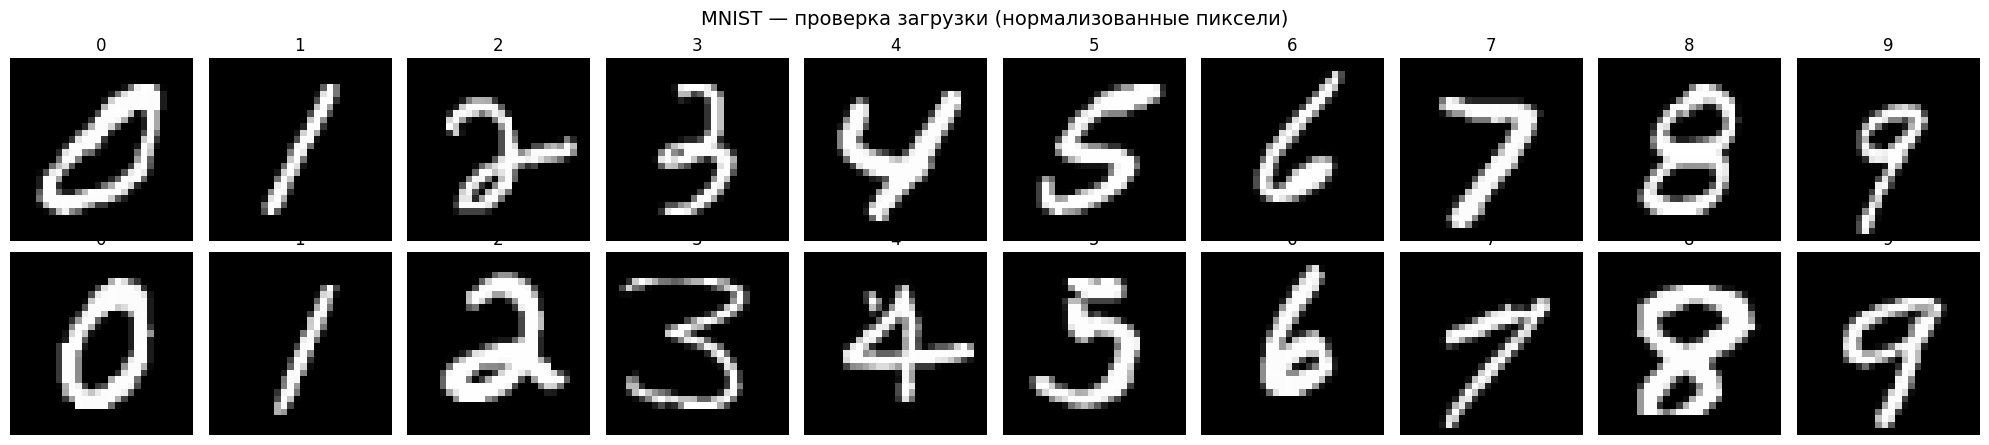

In [16]:
fig, axes = plt.subplots(2, 10, figsize=(20, 4.5))
for digit in range(10):
    idx = np.where(y_train == digit)[0]
    for row, i in enumerate(idx[:2]):
        axes[row, digit].imshow(X_train[i].reshape(28, 28), cmap='gray')
        axes[row, digit].set_title(f"{digit}")
        axes[row, digit].axis('off')
plt.suptitle("MNIST — проверка загрузки (нормализованные пиксели)", fontsize=14)
plt.tight_layout()
plt.show()

In [40]:
# Дерево без ограничений
tree_full = DecisionTreeClassifier(class_weight='balanced', random_state=42)
tree_full.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_full.predict(X_train))
val_acc   = accuracy_score(y_val,   tree_full.predict(X_val))
print(f"Дерево (без ограничений): train={train_acc:.3f}, val={val_acc:.3f}")

Дерево (без ограничений): train=1.000, val=0.875


In [38]:
for i in [5, 7, 9, 11, 15, 25]:
  tree_shallow = DecisionTreeClassifier(max_depth=i, random_state=42)
  tree_shallow.fit(X_train, y_train)

  train_acc = accuracy_score(y_train, tree_shallow.predict(X_train))
  val_acc   = accuracy_score(y_val,   tree_shallow.predict(X_val))
  print(f"Дерево (max_depth={i}):     train={train_acc:.3f}, val={val_acc:.3f}")

Дерево (max_depth=5):     train=0.675, val=0.668
Дерево (max_depth=7):     train=0.793, val=0.781
Дерево (max_depth=9):     train=0.870, val=0.841
Дерево (max_depth=11):     train=0.933, val=0.868
Дерево (max_depth=15):     train=0.986, val=0.875
Дерево (max_depth=25):     train=0.997, val=0.875


In [42]:
rf = RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

train_acc = accuracy_score(y_train, rf.predict(X_train))
val_acc   = accuracy_score(y_val,   rf.predict(X_val))
print(f"Random Forest: train={train_acc:.3f}, val={val_acc:.3f}")

Random Forest: train=1.000, val=0.968


In [44]:
for i in [5, 7, 9, 11, 15]:
  rf = RandomForestClassifier(class_weight='balanced', max_depth=i,  n_estimators=100, random_state=42)
  rf.fit(X_train, y_train)

  train_acc = accuracy_score(y_train, rf.predict(X_train))
  val_acc   = accuracy_score(y_val,   rf.predict(X_val))
  print(f"Random Forest (max_depth={i}): train={train_acc:.3f}, val={val_acc:.3f}")

Random Forest (max_depth=5): train=0.864, val=0.858
Random Forest (max_depth=7): train=0.913, val=0.906
Random Forest (max_depth=9): train=0.949, val=0.934
Random Forest (max_depth=11): train=0.979, val=0.948
Random Forest (max_depth=15): train=0.998, val=0.963
Random Forest (max_depth=25): train=1.000, val=0.968


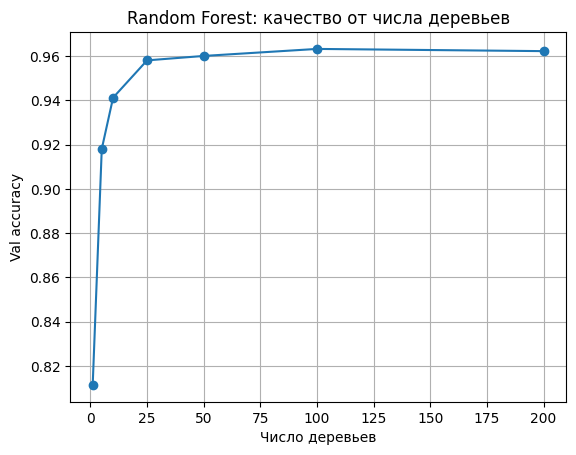

In [46]:
n_range = [1, 5, 10, 25, 50, 100, 200]
val_scores = []
for n in n_range:
    rf_n = RandomForestClassifier(class_weight='balanced', max_depth=15, n_estimators=n, random_state=42)
    rf_n.fit(X_train, y_train)
    val_scores.append(accuracy_score(y_val, rf_n.predict(X_val)))

plt.plot(n_range, val_scores, marker='o')
plt.xlabel("Число деревьев")
plt.ylabel("Val accuracy")
plt.title("Random Forest: качество от числа деревьев")
plt.grid(True)
plt.show()

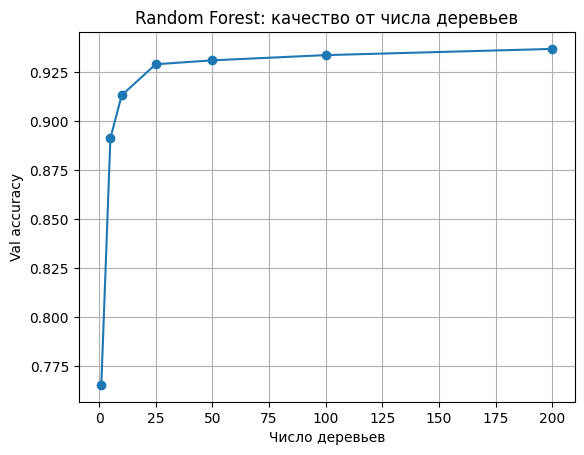

In [48]:
n_range = [1, 5, 10, 25, 50, 100, 200]
val_scores = []
for n in n_range:
    rf_n = RandomForestClassifier(class_weight='balanced', max_depth=9, n_estimators=n, random_state=42)
    rf_n.fit(X_train, y_train)
    val_scores.append(accuracy_score(y_val, rf_n.predict(X_val)))

plt.plot(n_range, val_scores, marker='o')
plt.xlabel("Число деревьев")
plt.ylabel("Val accuracy")
plt.title("Random Forest: качество от числа деревьев")
plt.grid(True)
plt.show()

In [58]:
gb = GradientBoostingClassifier(n_estimators=10, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train, y_train)

train_acc = accuracy_score(y_train, gb.predict(X_train))
val_acc   = accuracy_score(y_val,   gb.predict(X_val))
print(f"Gradient Boosting: train={train_acc:.3f}, val={val_acc:.3f}")

Gradient Boosting: train=0.842, val=0.838
